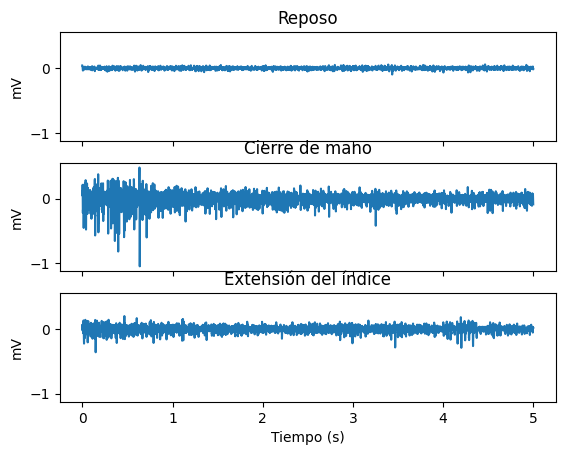

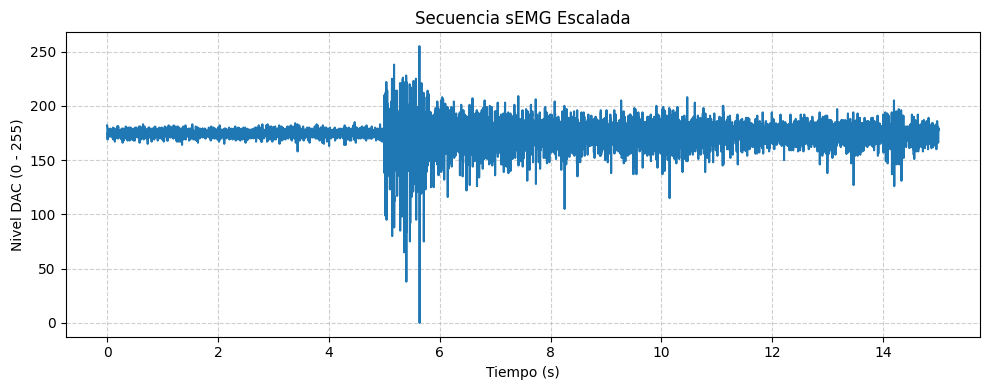

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#El código se creó en el entorno colab
!pip install -q wfdb
import wfdb
import numpy as np
import matplotlib.pyplot as plt

carpeta = "grabmyo/1.1.0/Session1/session1_participant1"
gestos = {"Reposo": 17, "Cierre de mano": 16, "Extensión del índice": 9}
canal = 11   # canal F12 → índice 11 en Python

senales = {}
for nombre_g, k in gestos.items():
    rec = wfdb.rdrecord(f"session1_participant1_gesture{k}_trial1", pn_dir=carpeta)
    senales[nombre_g] = rec.p_signal[:, canal]

fig, ax = plt.subplots(3, 1, sharex=True, sharey=True)
for a, (nombre_g, x) in zip(ax, senales.items()):
    a.plot(np.arange(len(x)) / rec.fs, x)
    a.set_title(nombre_g)
    a.set_ylabel("mV")
ax[-1].set_xlabel("Tiempo (s)")
plt.show()

# --- ETAPA B: Construcción, escalado y exportación ---

# 1. Concatenamos los registros en el orden solicitado
secuencia = np.concatenate((
    senales["Reposo"],
    senales["Cierre de mano"],
    senales["Extensión del índice"]))

# 2. Escalamos linealmente al rango de 8 bits (0 a 255)
min_val = np.min(secuencia)
max_val = np.max(secuencia)
secuencia_escalada = np.round(255 * (secuencia - min_val) / (max_val - min_val)).astype(int)

# 3. Graficamos la secuencia concatenada
plt.figure(figsize=(10, 4))
tiempo_total = np.arange(len(secuencia_escalada)) / rec.fs
plt.plot(tiempo_total, secuencia_escalada)
plt.title("Secuencia sEMG Escalada")
plt.xlabel("Tiempo (s)")
plt.ylabel("Nivel DAC (0 - 255)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 4. Exportamos el archivo semg.h
n_semg = len(secuencia_escalada)
fs_semg = rec.fs # Debería ser 2048 según la base de datos

with open("semg.h", "w") as f:
    f.write(f"const uint8_t SEMG[] = {{{', '.join(map(str, secuencia_escalada))}}};\n")
    f.write(f"const int N_SEMG = {n_semg};\n")
    f.write(f"const int FS_SEMG = {fs_semg};\n")

# Comando para descargar el archivo automáticamente
from google.colab import files
files.download("semg.h")